# Robustness of a PINN to Adversarial Input Perturbations (FGSM)

This notebook takes the two models trained in `01_heat_equation_pinn.ipynb`, a standard neural network and a PINN for the 1-D heat equation $u_t = 0.003\,u_{xx}$, and asks: **if the input $(x,t)$ is nudged by a small amount in the worst direction, how wrong can the model's answer become?**

## Method: FGSM for regression

The Fast Gradient Sign Method was designed for classifiers. Here it is adapted to a regression model $u_\theta(x,t)$. Because the exact solution $u(x,t)$ is known everywhere, the attack can target the model's *true error* at the perturbed point:

$$
(x,t)_{\text{adv}} = (x,t) + \varepsilon \odot \operatorname{sign}\Big(\nabla_{(x,t)}\,\big(u_\theta(x,t) - u(x,t)\big)^2\Big).
$$

Each input moves one step in the direction in which the model's squared error grows fastest, and the model is then scored at the new location against the exact solution there. The step is $\varepsilon$ times the **size of the domain in each coordinate** ($1$ in $x$, $100$ in $t$), so one $\varepsilon$ is the same relative shift in both. Perturbed points are clipped to the domain.

Reported quantity: the **mean absolute error against the exact solution** over a $101\times101$ test grid, before and after the attack, split into the region where the standard network had training data ($t\le20$) and the region where it did not.

> *Why not simply measure how much the output moves?* The true solution itself changes when the input changes, so an accurate model *should* move by the same amount. Output movement alone therefore says little about robustness. Measuring error against the truth does.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import heat_pinn as hp

plt.rcParams.update({"figure.dpi": 110})

model_nn = hp.load_model("models/standard_nn.pt")
model_pinn = hp.load_model("models/pinn.pt")
models = {"Standard NN": model_nn, "PINN": model_pinn}
colors = {"Standard NN": "tab:orange", "PINN": "tab:blue"}
print({name: sum(p.numel() for p in m.parameters()) for name, m in models.items()}, "parameters")

{'Standard NN': 1341, 'PINN': 1341} parameters


## 1. The attack

The attack is vectorised. The loss is summed over the batch, and since every sample depends only on its own input, the gradient of the sum with respect to the input is each sample's own gradient. `hp.exact_solution_torch` is a differentiable version of the exact solution, so the gradient accounts for how the truth changes as well as how the model does.

In [2]:
T_DATA_MAX = 20.0                       # end of the standard NN's training window
DOMAIN = hp.UB - hp.LB                  # per-coordinate scale for epsilon


def fgsm(model, xt, eps):
    # One-step FGSM on the model's true squared error. `eps` is a fraction of the domain size.
    xt = xt.clone().requires_grad_(True)
    loss = torch.sum((model(xt) - hp.exact_solution_torch(xt)) ** 2)
    (grad,) = torch.autograd.grad(loss, xt)
    xt_adv = xt.detach() + eps * DOMAIN * grad.sign()
    return torch.max(torch.min(xt_adv, hp.UB), hp.LB)        # stay inside the domain


def abs_error(model, xt):
    with torch.no_grad():
        return (model(xt) - hp.exact_solution_torch(xt)).abs().squeeze(1).numpy()


# 101 x 101 test grid over the whole domain
xs = np.linspace(*hp.X_RANGE, 101)
ts = np.linspace(*hp.T_RANGE, 101)
test_xt = hp.grid_inputs(xs, ts)
inside = (test_xt[:, 1] <= T_DATA_MAX).numpy()
print("test points:", len(test_xt), "| inside the data window:", inside.sum(), "| outside:", (~inside).sum())

test points: 10201 | inside the data window: 2121 | outside: 8080


## 2. Sweep over perturbation size

In [3]:
eps_values = [0.0, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.1]
err = {name: {"in": [], "out": []} for name in models}

for name, model in models.items():
    for eps in eps_values:
        e = abs_error(model, fgsm(model, test_xt, eps))
        err[name]["in"].append(e[inside].mean())
        err[name]["out"].append(e[~inside].mean())

print("Mean |u_model - u_exact| after the attack")
print(f"{'':>8} | {'inside data window (t <= %g)' % T_DATA_MAX:^31} | {'outside (t > %g)' % T_DATA_MAX:^31}")
print(f"{'eps':>8} | " + " | ".join(f"{n:^15}" for n in models) + " | " + " | ".join(f"{n:^15}" for n in models))
for i, eps in enumerate(eps_values):
    a = " | ".join(f"{err[n]['in'][i]:^15.4f}" for n in models)
    b = " | ".join(f"{err[n]['out'][i]:^15.4f}" for n in models)
    print(f"{eps:>8.4f} | {a} | {b}")

print()
print("Error growth factor at the largest epsilon (attacked / clean):")
for n in models:
    print(f"  {n:<12} inside: x{err[n]['in'][-1] / err[n]['in'][0]:.1f}   outside: x{err[n]['out'][-1] / err[n]['out'][0]:.2f}")

Mean |u_model - u_exact| after the attack
         |  inside data window (t <= 20)   |        outside (t > 20)        
     eps |   Standard NN   |      PINN       |   Standard NN   |      PINN      
  0.0000 |     0.0083      |     0.0063      |     0.6680      |     0.0015     
  0.0025 |     0.0097      |     0.0070      |     0.6819      |     0.0015     
  0.0050 |     0.0109      |     0.0076      |     0.6958      |     0.0016     
  0.0100 |     0.0129      |     0.0088      |     0.7236      |     0.0017     
  0.0200 |     0.0143      |     0.0101      |     0.7770      |     0.0019     
  0.0500 |     0.0193      |     0.0127      |     0.9147      |     0.0023     
  0.1000 |     0.0458      |     0.0141      |     1.0494      |     0.0020     

Error growth factor at the largest epsilon (attacked / clean):
  Standard NN  inside: x5.5   outside: x1.57
  PINN         inside: x2.2   outside: x1.35


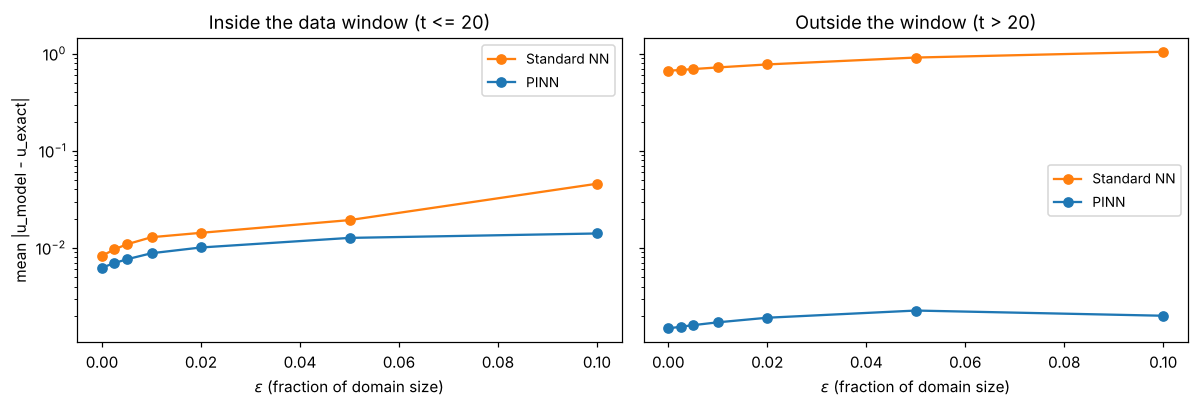

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, region, title in [(axes[0], "in", f"Inside the data window (t <= {T_DATA_MAX:g})"),
                          (axes[1], "out", f"Outside the window (t > {T_DATA_MAX:g})")]:
    for name in models:
        ax.semilogy(eps_values, err[name][region], "o-", color=colors[name], label=name)
    ax.set_title(title)
    ax.set_xlabel(r"$\varepsilon$ (fraction of domain size)")
    ax.legend(fontsize=9)
axes[0].set_ylabel("mean |u_model - u_exact|")
fig.tight_layout()
fig.savefig("figures/fgsm_epsilon_sweep.png", bbox_inches="tight")
plt.show()

## 3. Where does the attack hurt?

Adversarial error maps for one attack strength. Each pixel shows the error at the *perturbed* point that started from that location. Both maps share the same logarithmic colour scale.

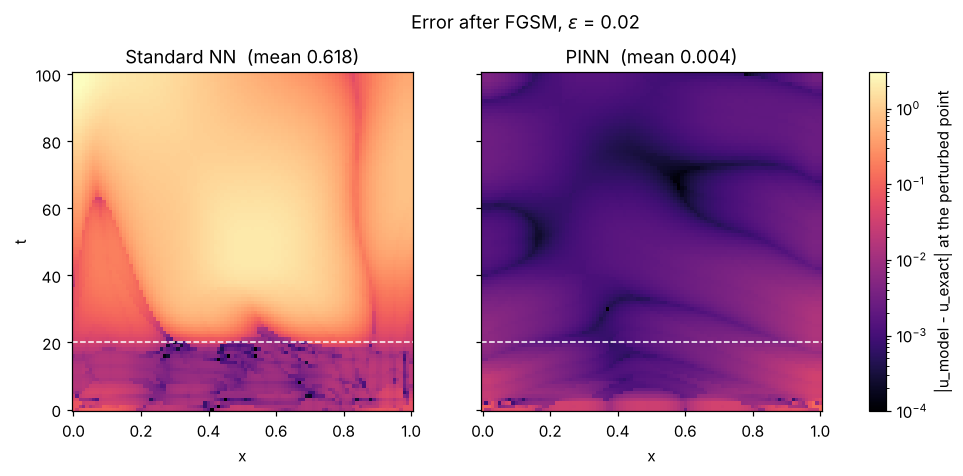

In [5]:
EPS = 0.02
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    e = abs_error(model, fgsm(model, test_xt, EPS)).reshape(len(xs), len(ts))
    im = ax.pcolormesh(xs, ts, np.maximum(e, 1e-6).T, shading="auto", cmap="magma",
                       norm=LogNorm(vmin=1e-4, vmax=3))
    ax.axhline(T_DATA_MAX, color="white", ls="--", lw=1)
    ax.set_title(f"{name}  (mean {e.mean():.3f})")
    ax.set_xlabel("x")
axes[0].set_ylabel("t")
fig.colorbar(im, ax=axes, label="|u_model - u_exact| at the perturbed point")
fig.suptitle(rf"Error after FGSM, $\varepsilon$ = {EPS}", y=1.02)
fig.savefig("figures/fgsm_error_maps.png", bbox_inches="tight")
plt.show()

## 4. A single time slice

The error along $x$ at a fixed time, for the clean inputs and after the attack.

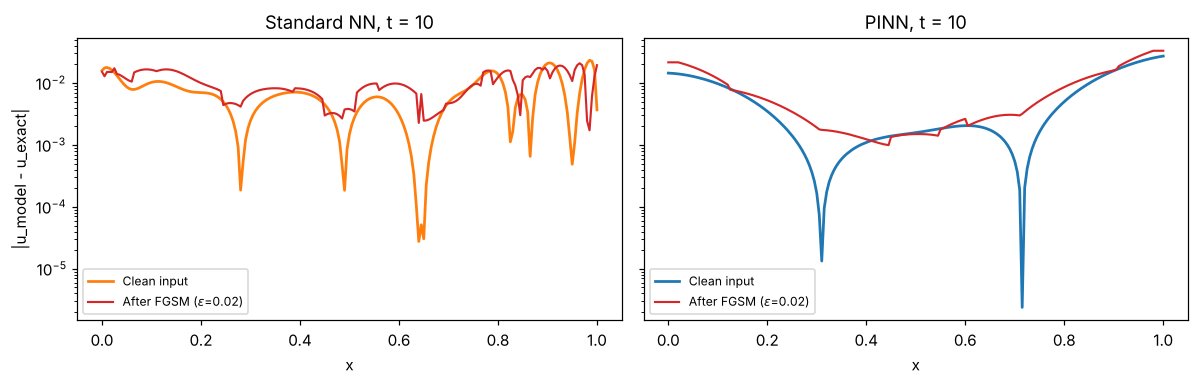

In [6]:
T_SLICE = 10.0       # inside the data window; try 60 to look at the extrapolation region
xt_line = hp.grid_inputs(np.linspace(*hp.X_RANGE, 201), [T_SLICE])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    ax.semilogy(xt_line[:, 0], np.maximum(abs_error(model, xt_line), 1e-7), color=colors[name], lw=1.8, label="Clean input")
    ax.semilogy(xt_line[:, 0], np.maximum(abs_error(model, fgsm(model, xt_line, EPS)), 1e-7), color="tab:red", lw=1.4,
                label=rf"After FGSM ($\varepsilon$={EPS})")
    ax.set_title(f"{name}, t = {T_SLICE:g}")
    ax.set_xlabel("x")
    ax.legend(fontsize=8)
axes[0].set_ylabel("|u_model - u_exact|")
fig.tight_layout()
fig.savefig("figures/fgsm_slice.png", bbox_inches="tight")
plt.show()

## Reading the results

**Clean accuracy.** Inside the data window both models are accurate (mean error 0.008 for the standard network, 0.006 for the PINN). Outside it the standard network is wrong by about 0.67 on average while the PINN is wrong by 0.0015, roughly 450 times smaller. This gap dominates everything else below.

**Inside the window, the standard network is more fragile.** At $\varepsilon = 0.1$ its error grows 5.5 times, from 0.008 to 0.046. The PINN's grows 2.2 times, from 0.006 to 0.014. The standard network is only constrained at its observation points, so a small shift can land where it is wrong. The PDE residual constrains the PINN on a much larger set of points, and its error changes more gently.

**Outside the window, the relative growth is similar** (1.6 times for the standard network, 1.35 times for the PINN). The PINN's advantage there comes mostly from being accurate to begin with: even at $\varepsilon = 0.1$ its attacked error (0.002) is far below the standard network's *clean* error (0.67).

**Caveats.**
* One training run per model (one seed, one architecture), so differences between the models are indicative, not statistically established. Repeating over several seeds is the obvious next step.
* A single-step attack with fixed budgets. A stronger iterative attack (PGD) would find larger errors for both models.
* "Robustness" here means error against the known truth at nearby inputs. It is not a certified bound, and a PINN is only as reliable as the residual it was trained on.